# 06 — Intelligence artificielle explicable (XAI)

## Objectif du notebook

Comprendre **quelles variables (capteurs) influencent le plus** les prédictions du RUL,
avec deux méthodes simples :

1. **Feature Importance** des modèles à base d'arbres (Random Forest, Gradient Boosting).
2. **Permutation Importance**, applicable à n'importe quel modèle.

Les résultats sont enregistrés dans `metrics.json` (consultables via l'API `GET /models/metrics`). L'interface utilisateur n'affiche pas ces informations techniques.

## 1. Importations

In [1]:
# Importation des bibliothèques
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 90
RANDOM_STATE = 42

In [2]:
validation_set = pd.read_csv("../data/processed/validation_set.csv")
preprocessing = joblib.load("../models/preprocessing.pkl")
feature_columns = preprocessing["feature_columns"]
selected_sensors = preprocessing["selected_sensors"]

X_validation = preprocessing["scaler"].transform(validation_set[feature_columns])
y_validation = validation_set["RUL"].values

with open("../models/metrics.json", encoding="utf-8") as file:
    metrics = json.load(file)
selected_model_name = metrics["selected_model"]

rul_model = joblib.load("../models/rul_model.pkl")
random_forest_model = joblib.load("../models/candidates/random_forest.pkl")
gradient_boosting_model = joblib.load("../models/candidates/gradient_boosting.pkl")
print("Modèle sélectionné :", selected_model_name)

Modèle sélectionné : Gradient Boosting Regressor


## 2. Feature Importance (importance basée sur les arbres)

Dans un arbre de décision, chaque division réduit l'erreur. La *feature importance* d'une variable
est la **réduction totale de l'erreur** obtenue grâce aux divisions qui utilisent cette variable,
moyennée sur tous les arbres et normalisée pour que la somme fasse 1.

- ✅ Gratuite : calculée pendant l'entraînement.
- ❌ Peut favoriser les variables avec beaucoup de valeurs différentes, et partage
  l'importance entre variables corrélées.

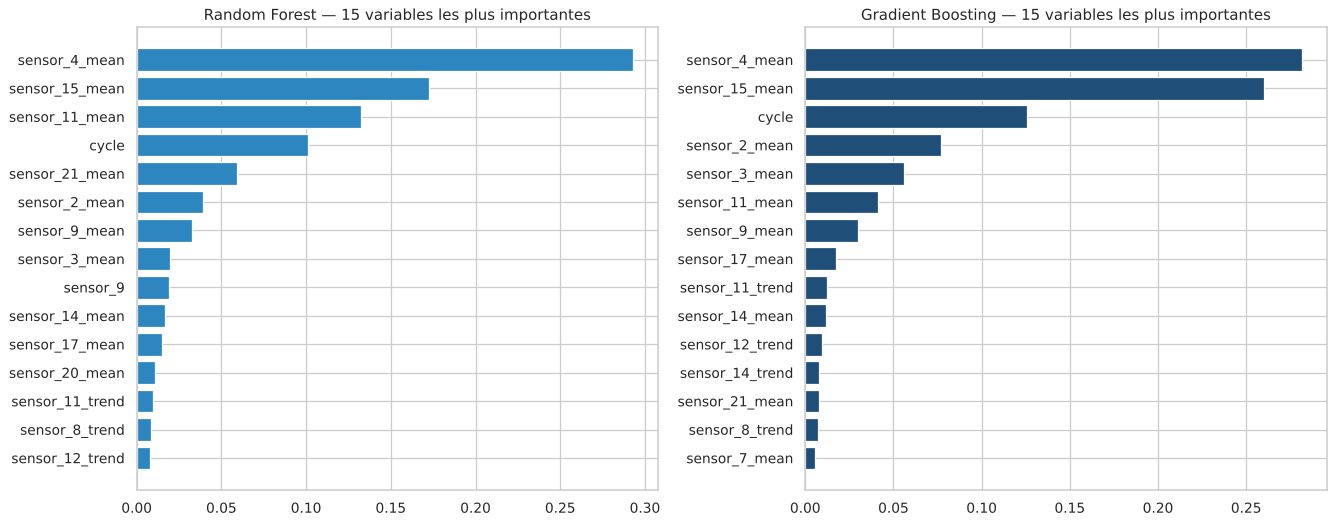

In [3]:
def importance_table(model, columns):
    """Retourne un tableau trié des importances d'un modèle à base d'arbres."""
    table = pd.DataFrame({"feature": columns, "importance": model.feature_importances_})
    return table.sort_values("importance", ascending=False).reset_index(drop=True)


random_forest_importance = importance_table(random_forest_model, feature_columns)
gradient_boosting_importance = importance_table(gradient_boosting_model, feature_columns)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
top_rf = random_forest_importance.head(15)
axes[0].barh(top_rf["feature"][::-1], top_rf["importance"][::-1], color="#2e86c1")
axes[0].set_title("Random Forest — 15 variables les plus importantes")
top_gb = gradient_boosting_importance.head(15)
axes[1].barh(top_gb["feature"][::-1], top_gb["importance"][::-1], color="#1f4e79")
axes[1].set_title("Gradient Boosting — 15 variables les plus importantes")
plt.tight_layout()
plt.show()

## 3. Permutation Importance

**Principe :** on mélange aléatoirement les valeurs d'**une seule variable** dans les données
de validation, puis on mesure **de combien l'erreur du modèle augmente**.
- Si l'erreur augmente beaucoup → la variable est importante.
- Si l'erreur ne change pas → le modèle n'utilise pas vraiment cette variable.

On l'applique au **modèle sélectionné**, sur les données de **validation** (non vues à l'entraînement).
Score utilisé : RMSE (négatif dans scikit-learn, d'où une importance = augmentation du RMSE).

In [4]:
# Échantillon de 2000 lignes de validation pour un calcul rapide
sample_indices = np.random.RandomState(RANDOM_STATE).choice(len(X_validation), 2000, replace=False)

permutation_result = permutation_importance(
    rul_model,
    X_validation[sample_indices],
    y_validation[sample_indices],
    scoring="neg_root_mean_squared_error",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

permutation_table = pd.DataFrame({
    "feature": feature_columns,
    "importance": permutation_result.importances_mean,
    "std": permutation_result.importances_std,
}).sort_values("importance", ascending=False).reset_index(drop=True)

permutation_table.head(15).round(3)

,feature,importance,std
0,cycle,5.489,0.232
1,sensor_15_mean,2.211,0.157
2,sensor_4_mean,1.675,0.095
3,sensor_2_mean,0.837,0.058
4,sensor_12_trend,0.708,0.057
5,sensor_8_trend,0.694,0.049
6,sensor_3_mean,0.567,0.044
7,sensor_9_mean,0.489,0.061
8,sensor_13_trend,0.431,0.060
9,sensor_11_trend,0.423,0.057


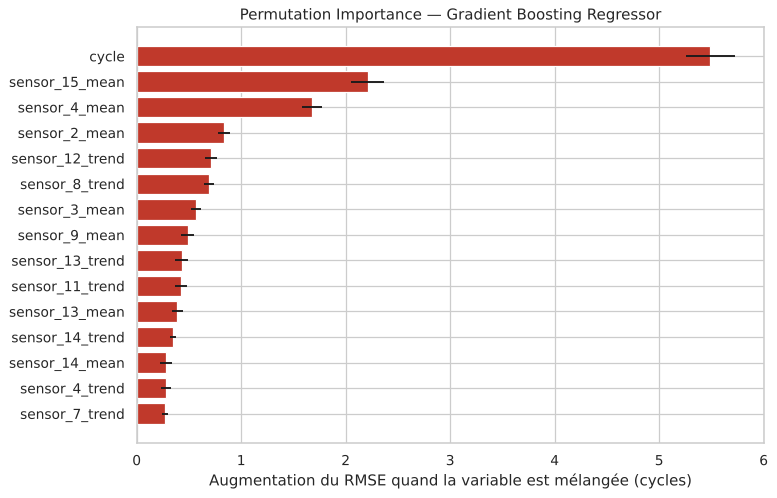

In [5]:
top_permutation = permutation_table.head(15)
plt.figure(figsize=(9, 6))
plt.barh(top_permutation["feature"][::-1], top_permutation["importance"][::-1],
         xerr=top_permutation["std"][::-1], color="#c0392b")
plt.title("Permutation Importance — " + selected_model_name)
plt.xlabel("Augmentation du RMSE quand la variable est mélangée (cycles)")
plt.show()

## 4. Importance par capteur

Chaque capteur est représenté par 3 variables (valeur, moyenne mobile, variation).
On additionne leurs importances de permutation pour obtenir l'importance **globale du capteur**.

In [6]:
sensor_names = {
    "sensor_2": "T24 temp. sortie LPC", "sensor_3": "T30 temp. sortie HPC",
    "sensor_4": "T50 temp. sortie LPT", "sensor_7": "P30 pression sortie HPC",
    "sensor_8": "Nf vitesse ventilateur", "sensor_9": "Nc vitesse cœur",
    "sensor_11": "Ps30 pression statique HPC", "sensor_12": "phi rapport carburant",
    "sensor_13": "NRf vitesse corrigée ventilateur", "sensor_14": "NRc vitesse corrigée cœur",
    "sensor_15": "BPR taux de dilution", "sensor_17": "htBleed enthalpie",
    "sensor_20": "W31 refroidissement HPT", "sensor_21": "W32 refroidissement LPT",
}

sensor_rows = []
for sensor in selected_sensors:
    total = 0.0
    for index in range(len(permutation_table)):
        feature = permutation_table.loc[index, "feature"]
        if feature == sensor or feature.startswith(sensor + "_"):
            total = total + permutation_table.loc[index, "importance"]
    sensor_rows.append({"sensor": sensor, "description": sensor_names[sensor], "importance": total})

sensor_importance = pd.DataFrame(sensor_rows).sort_values("importance", ascending=False)
sensor_importance = sensor_importance.reset_index(drop=True)

cycle_importance = permutation_table[permutation_table["feature"] == "cycle"]["importance"].iloc[0]
print("Importance de la variable 'cycle' : %.3f" % cycle_importance)
sensor_importance.round(3)

Importance de la variable 'cycle' : 5.489


,sensor,description,importance
0,sensor_15,BPR taux de dilution,2.368
1,sensor_4,T50 temp. sortie LPT,1.974
2,sensor_2,T24 temp. sortie LPC,0.942
3,sensor_12,phi rapport carburant,0.896
4,sensor_13,NRf vitesse corrigée ventilateur,0.819
5,sensor_8,Nf vitesse ventilateur,0.717
6,sensor_3,T30 temp. sortie HPC,0.631
7,sensor_14,NRc vitesse corrigée cœur,0.621
8,sensor_9,Nc vitesse cœur,0.529
9,sensor_11,Ps30 pression statique HPC,0.520


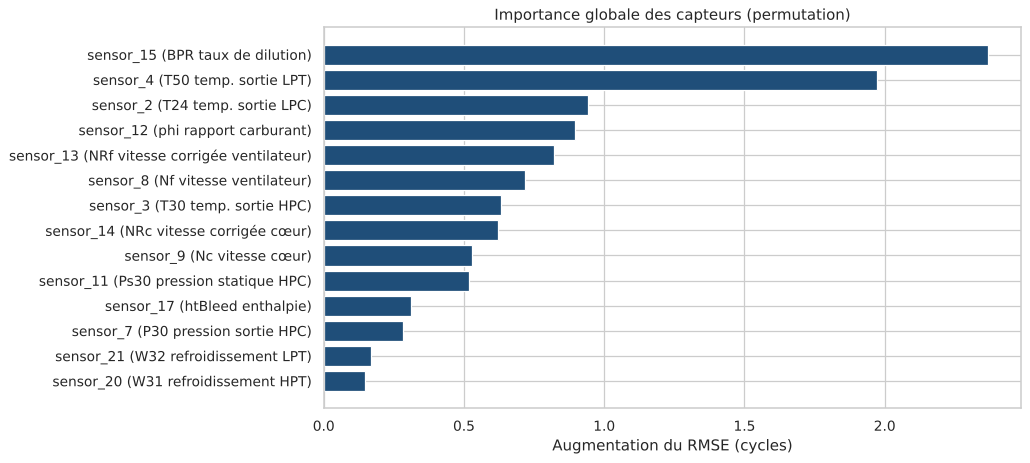

In [7]:
plt.figure(figsize=(10, 5.5))
labels = sensor_importance["sensor"] + " (" + sensor_importance["description"] + ")"
plt.barh(labels[::-1], sensor_importance["importance"][::-1], color="#1f4e79")
plt.title("Importance globale des capteurs (permutation)")
plt.xlabel("Augmentation du RMSE (cycles)")
plt.show()

## 5. Interprétation et précautions

- Les variables les plus importantes sont celles déjà identifiées dans l'EDA comme fortement
  corrélées au RUL : la cohérence entre les deux analyses renforce la confiance dans le modèle.
- Les **moyennes mobiles** et les **variations** sont bien plus importantes que les valeurs brutes :
  le lissage du bruit et la tendance sont utiles au modèle.
- La variable `cycle` (âge du moteur) est la plus importante. C'est logique (un moteur âgé est plus
  proche de la panne), mais c'est aussi une **limite** : le modèle s'appuie en partie sur l'âge moyen
  des moteurs du dataset, ce qui pourrait moins bien se généraliser à des moteurs différents.

⚠️ **Attention :** l'importance d'un capteur indique qu'il est **utile au modèle pour prédire**,
**pas** qu'il est la **cause** d'une panne. Un capteur peut simplement *refléter* une dégradation
située ailleurs dans le moteur. Par ailleurs, quand deux capteurs sont corrélés, leur importance
peut se répartir entre eux de façon arbitraire.

## 6. Sauvegarde dans metrics.json

In [8]:
def table_to_list(table, top_n):
    """Convertit les premières lignes d'un tableau d'importance en liste de dictionnaires."""
    result = []
    for index in range(min(top_n, len(table))):
        result.append({
            "feature": table.loc[index, "feature"],
            "importance": round(float(table.loc[index, "importance"]), 4),
        })
    return result


sensor_list = []
for index in range(len(sensor_importance)):
    sensor_list.append({
        "sensor": sensor_importance.loc[index, "sensor"],
        "description": sensor_importance.loc[index, "description"],
        "importance": round(float(sensor_importance.loc[index, "importance"]), 4),
    })

# Importance "arbres" du modèle sélectionné (si compatible)
if hasattr(rul_model, "feature_importances_"):
    selected_feature_importance = table_to_list(importance_table(rul_model, feature_columns), 15)
else:
    selected_feature_importance = []

metrics["explainability"] = {
    "feature_importance": selected_feature_importance,
    "permutation_importance": table_to_list(permutation_table, 15),
    "sensor_importance": sensor_list,
    "cycle_importance": round(float(cycle_importance), 4),
}

with open("../models/metrics.json", "w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=2, ensure_ascii=False)
print("metrics.json mis à jour.")

metrics.json mis à jour.


## 7. Conclusion

- Deux méthodes simples (Feature Importance et Permutation Importance) donnent une vision
  **globale** de l'influence des variables.
- Les capteurs les plus influents sont affichés ci-dessus.
- Ces importances aident à comprendre le modèle, mais **ne prouvent pas de lien de causalité** avec une panne.